# 01. Eksploracyjna analiza danych i kontrola jakości

Zbiór: *Brain Tumor MRI Dataset* (Masoud Nickparvar, Kaggle). Cztery klasy: glejak (`glioma`),
oponiak (`meningioma`), brak guza (`notumor`) i guz przysadki (`pituitary`).

Plan notatnika:
1. liczność klas i pochodzenie zbalansowanej wersji zbioru,
2. rozdzielczości, tryby kolorów i kanały,
3. jasność obrazów w klasach,
4. przykładowe obrazy,
5. duplikaty i wyciek między `Training` i `Testing` (najważniejsza część).

In [1]:
import sys
sys.path.insert(0, '..')

from collections import Counter

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

from src.data import CLASSES, FIG_DIR, METRICS_DIR, ROOT, list_images
from src.duplicates import PHASH_THRESHOLD

FIG_DIR.mkdir(parents=True, exist_ok=True)
df = pd.concat([list_images('Training'), list_images('Testing')], ignore_index=True)
len(df)

7200

## 1. Liczność klas

In [2]:
counts = df.groupby(['split', 'cls']).size().unstack()
counts_aug = df[df.aug].groupby(['split', 'cls']).size().unstack()
print(counts)
print('\nw tym pliki *-aug-* (sztuczne kopie):')
print(counts_aug)

cls       glioma  meningioma  notumor  pituitary
split                                           
Testing      400         400      400        400
Training    1400        1400     1400       1400

w tym pliki *-aug-* (sztuczne kopie):
cls       meningioma
split               
Testing          103
Training         100


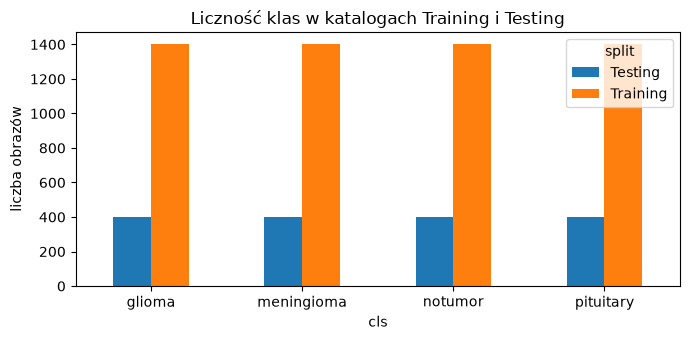

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
counts.T.plot.bar(ax=ax, rot=0)
ax.set_ylabel('liczba obrazów')
ax.set_title('Liczność klas w katalogach Training i Testing')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_klasy.png', dpi=150)
plt.show()

Pobrana wersja zbioru ma 7200 obrazów: po 1400 na klasę w `Training` i po 400 w `Testing`.
Starszy opis zbioru (i stara wersja README) podaje 7023 obrazy i liczności 1321/1339/1595/1457.
Wyjaśnienie widać w nazwach plików: klasę `meningioma` dopełniono plikami `Tr-aug-me_*` (100)
i `Te-aug-me_*` (103). To nie są nowe badania, tylko przekształcone kopie istniejących obrazów
(sprawdzone w sekcji 5). Pozostałe klasy też mają inne liczności niż w opisie, więc autor zbioru
musiał je także przyciąć lub uzupełnić. Wniosek: balans 1400/400 jest sztuczny, a pliki `aug`
usuwamy z treningu i z oczyszczonego testu.

## 2. Rozdzielczości, tryby kolorów i kanały

In [4]:
info = []
for p in df.path:
    im = Image.open(ROOT / p)
    a = np.asarray(im.convert('RGB')).astype(int)
    # średnia różnica między kanałami R i B (0 = obraz w pełni szary)
    info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode,
                 'diff_rgb': np.abs(a[..., 0] - a[..., 2]).mean()})
info = pd.DataFrame(info)
df = pd.concat([df, info], axis=1)
print('tryby:', Counter(df['mode']))
print('liczba różnych rozdzielczości:', df.groupby(['w', 'h']).ngroups)
print('obrazy z różnymi kanałami RGB:', (df.diff_rgb > 0).sum(),
      ', ze średnią różnicą > 1:', (df.diff_rgb > 1).sum(), ', > 5:', (df.diff_rgb > 5).sum())
print(df[df.diff_rgb > 0].cls.value_counts())

tryby: Counter({'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1})
liczba różnych rozdzielczości: 447
obrazy z różnymi kanałami RGB: 129 , ze średnią różnicą > 1: 59 , > 5: 2
cls
notumor    129
Name: count, dtype: int64


In [5]:
df['is_512'] = (df.w == 512) & (df.h == 512)
size_tab = df.groupby('cls').agg(udzial_512x512=('is_512', 'mean'), min_szer=('w', 'min'),
                                 mediana_szer=('w', 'median'), max_szer=('w', 'max'))
size_tab.round(3)

,udzial_512x512,min_szer,mediana_szer,max_szer
cls,,,,
glioma,0.958,175,512.0,640
meningioma,0.861,174,512.0,1275
notumor,0.011,150,228.0,1375
pituitary,0.956,201,512.0,1365


Obrazy mają 447 różnych rozdzielczości, ale rozkład zależy od klasy: prawie wszystkie obrazy
glejaków, oponiaków i guzów przysadki mają 512x512 (zbiór figshare), a obrazy `notumor` mają
różne rozmiary (pochodzą z innych źródeł - SARTAJ i Br35H). To pierwsza przesłanka, że sieć może
rozpoznawać **źródło obrazu** (rozmiar, kadrowanie, ramka) zamiast guza. Wszystkie obrazy
skalujemy do 224x224, ale ślady kadrowania i proporcji zostają.

Pliki są zapisane w trybie `L` (szarość) albo `RGB`. W obrazach RGB kanały są prawie zawsze
identyczne; 129 plików (prawie wyłącznie `notumor`) ma lekkie zabarwienie, ale średnia różnica
między kanałami przekracza 5 poziomów jasności tylko w 2 plikach. Dlatego pracujemy na jednym
kanale szarości - zabarwienie znika i nie może stać się wskazówką dla modelu.

## 3. Jasność obrazów w klasach

In [6]:
def stats(p):
    a = np.asarray(Image.open(ROOT / p).convert('L').resize((224, 224)), dtype=np.float32)
    return a.mean(), (a > 20).mean()   # średnia jasność, udział pikseli "nie-tła"

df[['mean_int', 'frac_fg']] = [stats(p) for p in df.path]
df.groupby('cls')[['mean_int', 'frac_fg']].describe().round(2)[[('mean_int', 'mean'), ('mean_int', '50%'), ('mean_int', 'std'), ('frac_fg', 'mean')]]

mean_int               frac_fg
               mean    50%    std    mean
cls                                      
glioma        34.74  32.64  11.53    0.47
meningioma    44.69  41.30  15.59    0.51
notumor       61.43  57.08  21.21    0.57
pituitary     49.37  49.62   8.86    0.63

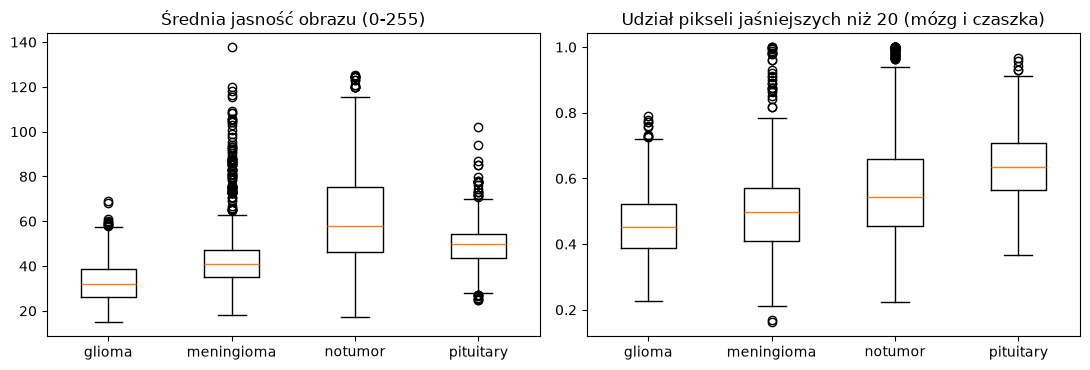

średnia jasność w treningu (skala 0-1): 0.184


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
tr = df[df.split == 'Training']
axes[0].boxplot([tr[tr.cls == c].mean_int for c in CLASSES], tick_labels=CLASSES)
axes[0].set_title('Średnia jasność obrazu (0-255)')
axes[1].boxplot([tr[tr.cls == c].frac_fg for c in CLASSES], tick_labels=CLASSES)
axes[1].set_title('Udział pikseli jaśniejszych niż 20 (mózg i czaszka)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_jasnosc.png', dpi=150)
plt.show()
print('średnia jasność w treningu (skala 0-1):', round(tr.mean_int.mean() / 255, 3))

In [8]:
# liczby z EDA zapisujemy do pliku, z którego korzysta generator raportu
import json
eda_stats = {
    'n_resolutions': int(df.groupby(['w', 'h']).ngroups),
    'frac_512': df.groupby('cls').is_512.mean().round(4).to_dict(),
    'mean_intensity': tr.groupby('cls').mean_int.mean().round(2).to_dict(),
    'n_rgb_differs': int((df.diff_rgb > 0).sum()),
    'train_mean': round(float(tr.mean_int.mean() / 255), 3),
}
json.dump(eda_stats, open(METRICS_DIR / 'eda_stats.json', 'w'), indent=1)
eda_stats

{'n_resolutions': 447,
 'frac_512': {'glioma': 0.9578,
  'meningioma': 0.8611,
  'notumor': 0.0111,
  'pituitary': 0.9556},
 'mean_intensity': {'glioma': 33.09,
  'meningioma': 43.36,
  'notumor': 61.73,
  'pituitary': 49.43},
 'n_rgb_differs': 129,
 'train_mean': 0.184}

Średnia jasność różni się między klasami: obrazy `glioma` są wyraźnie ciemniejsze niż `notumor`.
Nie wynika to z samego guza (guz zajmuje mały fragment obrazu), tylko ze sposobu akwizycji:
inne sekwencje MRI (T1 z kontrastem, T2, FLAIR), inne okno wyświetlania i inne źródło danych.
Ryzyko: model może nauczyć się „kontrastu akwizycji” zamiast cech guza. Dlatego:
- nie stosujemy augmentacji jasności ani kontrastu (zmieniłaby informację, która w MRI ma znaczenie,
  a przy okazji ukryłaby problem zamiast go ujawnić),
- w notatniku 05 sprawdzamy Grad-CAM-em, na jaki obszar patrzy model.

## 4. Przykładowe obrazy

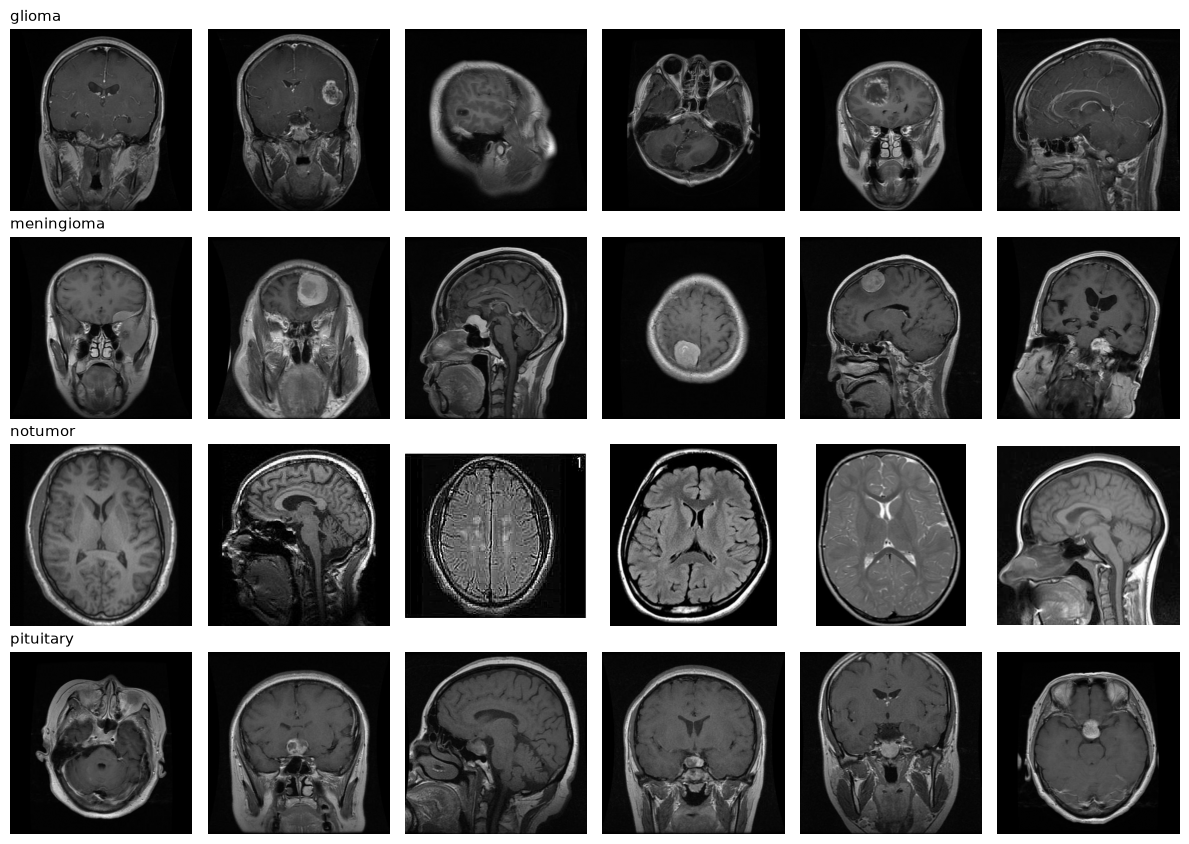

In [9]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 6, figsize=(12, 8.5))
for r, cls in enumerate(CLASSES):
    paths = df[(df.split == 'Training') & (df.cls == cls) & ~df.aug].path.to_numpy()
    for c, p in enumerate(rng.choice(paths, 6, replace=False)):
        axes[r, c].imshow(Image.open(ROOT / p).convert('L'), cmap='gray')
        axes[r, c].axis('off')
    axes[r, 0].set_title(cls, loc='left', fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_przyklady.png', dpi=120)
plt.show()

W każdej klasie są przekroje w trzech płaszczyznach (osiowej, czołowej, strzałkowej).
Obrazy z guzami to głównie sekwencja T1 po kontraście (zbiór figshare, 512x512), a obrazy
`notumor` pochodzą z innych źródeł i mają różne sekwencje (T1, T2, FLAIR), kadrowanie
i czasem znaczniki w rogu obrazu. To ta sama przesłanka co przy rozdzielczościach: klasa
jest powiązana ze źródłem danych.

## 5. Duplikaty i wyciek między Training i Testing

Zbiór nie zawiera identyfikatora pacjenta, więc nie da się zrobić podziału „per pacjent”
(Leave-One-Group-Out z wykładu 4). Zbiór powstał z połączenia kilku źródeł (figshare, SARTAJ,
Br35H), więc mogą w nim być te same obrazy albo sąsiednie przekroje tego samego badania.
Sprawdzamy to dwiema metodami:
- **MD5 pliku** - identyczne pliki,
- **perceptual hash (pHash)** - 64-bitowy skrót obrazu oparty na DCT; podobne obrazy mają
  skróty różniące się na niewielu bitach (odległość Hamminga). Wykrywa kopie po zmianie
  rozmiaru, kompresji czy niewielkiej zmianie kontrastu.

Obliczenia są w `src/duplicates.py` (uruchomione poleceniem `python -m src.duplicates`);
tutaj wczytujemy wyniki.

In [10]:
dup = pd.read_csv(METRICS_DIR / 'duplicates.csv', dtype={'phash': str, 'md5': str})
pairs = pd.read_csv(METRICS_DIR / 'duplicate_pairs.csv')
md5_groups = dup.groupby('md5').size()
print('grupy identycznych plików (MD5):', (md5_groups > 1).sum(),
      ', plików w tych grupach:', md5_groups[md5_groups > 1].sum())
print('w tym pary MD5 między Training i Testing:',
      int(((pairs.split_a != pairs.split_b) & pairs.same_md5).sum()))
print(f'pary niemal-duplikatów (pHash, odległość <= {PHASH_THRESHOLD}):', len(pairs))
pairs.assign(typ=pairs.split_a.str[:2] + '-' + pairs.split_b.str[:2],
             ta_sama_klasa=pairs.cls_a == pairs.cls_b).groupby(['typ', 'ta_sama_klasa']).size()

grupy identycznych plików (MD5): 153 , plików w tych grupach: 340
w tym pary MD5 między Training i Testing: 0
pary niemal-duplikatów (pHash, odległość <= 4): 5893


typ    ta_sama_klasa
Te-Te  False               5
       True              411
Tr-Te  False              18
       True             2009
Tr-Tr  False              24
       True             3426
dtype: int64

### Dobór progu
Obejrzeliśmy losowe pary przy różnych odległościach Hamminga. Przy odległości 0-2 są to te same
obrazy (czasem przycięte inaczej albo z innym kontrastem), przy 4 - ten sam obraz albo sąsiedni
przekrój tego samego badania, przy 6 i więcej coraz częściej różne osoby o podobnym przekroju.
Przyjmujemy próg **4** (ostrożny: lepiej usunąć z testu kilka niezależnych obrazów niż zostawić
kopie z treningu).

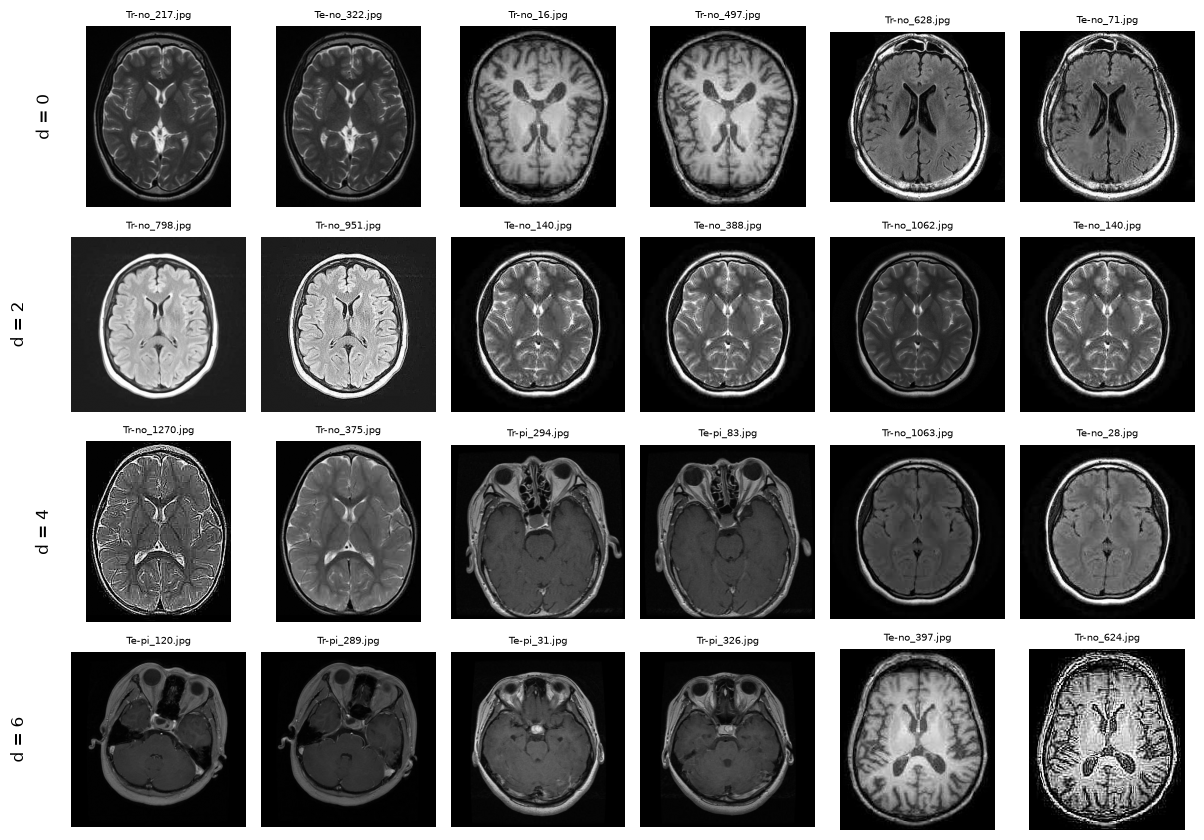

In [11]:
paths_all = dup.path.to_numpy()
bits = np.array([[c == '1' for c in h] for h in dup.phash])
rng = np.random.default_rng(1)
fig, axes = plt.subplots(4, 6, figsize=(12, 8.5))
for r, d in enumerate([0, 2, 4, 6]):
    if d <= PHASH_THRESHOLD:
        cand = pairs[pairs.dist == d][['path_a', 'path_b']].to_numpy()
    else:
        # par z odległością 6 nie ma w pliku (powyżej progu) - szukamy ich wśród obrazów testowych
        cand = []
        test_idx = np.where(dup.split == 'Testing')[0]
        for i in rng.choice(test_idx, 400, replace=False):
            dist = (bits != bits[i]).sum(1)
            dist[i] = 99
            j = np.where(dist == d)[0]
            if len(j):
                cand.append((paths_all[i], paths_all[j[0]]))
        cand = np.array(cand)
    for c, k in enumerate(rng.choice(len(cand), 3, replace=False)):
        for s in range(2):
            ax = axes[r, 2 * c + s]
            ax.imshow(Image.open(ROOT / cand[k][s]).convert('L'), cmap='gray')
            ax.set_title(cand[k][s].split('/')[-1], fontsize=7)
            ax.axis('off')
    axes[r, 0].text(-0.35, 0.5, f'd = {d}', transform=axes[r, 0].transAxes, fontsize=12, va='center', rotation=90)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_pary_phash.png', dpi=110)
plt.show()

### Wyciek do zbioru testowego w zależności od progu

In [12]:
leak = pd.read_csv(METRICS_DIR / 'leak_vs_threshold.csv')
leak

,threshold,test_with_train_twin,glioma,meningioma,notumor,pituitary
0,0,370,6,105,257,2
1,2,505,24,124,328,29
2,4,714,86,173,353,102
3,6,981,172,240,363,206
4,8,1248,254,314,374,306


Nawet przy progu 0 (obrazy praktycznie identyczne) 370 z 1600 obrazów testowych ma swojego
bliźniaka w treningu, z czego 257 to klasa `notumor`. Przy progu 4 jest to 714 obrazów,
w tym 353 z 400 obrazów `notumor`. Wynik na oryginalnym teście jest więc częściowo
„sprawdzaniem pamięci” modelu - szczególnie dla klasy `notumor`.

### Pary z różnymi etykietami

pary z różnymi klasami: 47
cls_a       cls_b     
glioma      meningioma    31
            notumor        3
meningioma  glioma         8
            notumor        1
notumor     glioma         1
            meningioma     1
pituitary   meningioma     2
dtype: int64


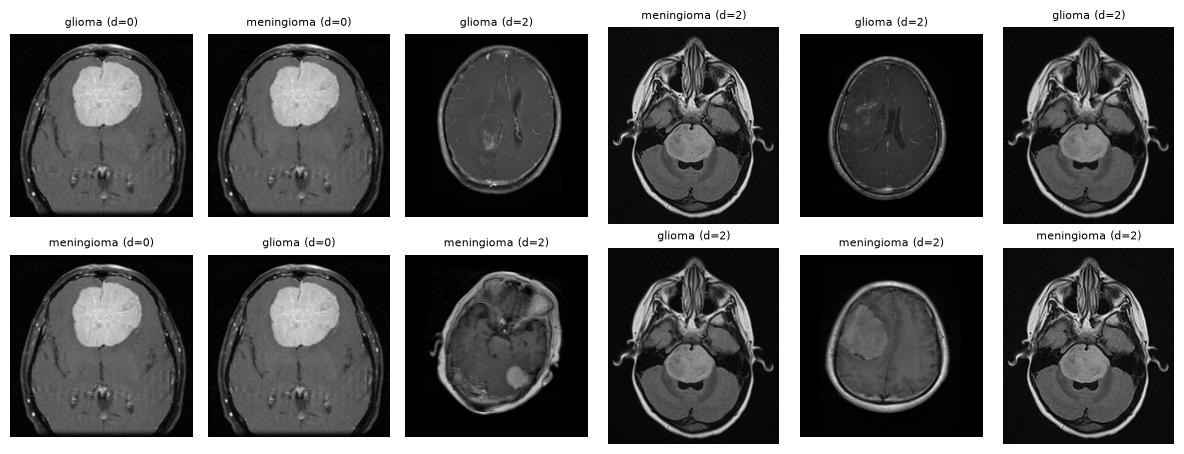

In [13]:
conflict = pairs[pairs.cls_a != pairs.cls_b]
print('pary z różnymi klasami:', len(conflict))
print(conflict.groupby(['cls_a', 'cls_b']).size())
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
examples = conflict.sort_values('dist').drop_duplicates('path_a').drop_duplicates('path_b')
for c, (_, row) in enumerate(examples.head(6).iterrows()):
    for s, key in enumerate(['a', 'b']):
        ax = axes[s, c]
        ax.imshow(Image.open(ROOT / row[f'path_{key}']).convert('L'), cmap='gray')
        ax.set_title(f"{row[f'cls_{key}']} (d={row.dist})", fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_konflikty_etykiet.png', dpi=110)
plt.show()

Kilkadziesiąt par to ten sam (lub sąsiedni) przekrój z różnymi etykietami - głównie glejak
i oponiak. To szum etykiet, który ogranicza osiągalną dokładność dla tej pary klas i jest
jedną z przyczyn błędów omawianych w notatniku 05. Nie poprawiamy etykiet (nie jesteśmy
radiologami), ale raportujemy problem.

### Skąd pochodzą obrazy `aug`?
Dla każdego pliku `*-aug-me_*` szukamy najbliższego oryginalnego obrazu oponiaka,
porównując pHash także z odbitymi i obróconymi wersjami oryginałów.

In [14]:
orig = dup[(dup.cls == 'meningioma') & ~dup.aug]
aug = dup[dup.aug]
variants = {'bez zmian': lambda g: g, 'odbicie poziome': ImageOps.mirror,
            'odbicie pionowe': ImageOps.flip, 'obrót 180': lambda g: g.rotate(180)}
ref_bits, ref_info = [], []
for p in orig.path:
    g = Image.open(ROOT / p).convert('L')
    for name, f in variants.items():
        ref_bits.append(imagehash.phash(f(g)).hash.flatten())
        ref_info.append((p, name))
ref_bits = np.array(ref_bits)
match = []
for p in aug.path:
    h = imagehash.phash(Image.open(ROOT / p).convert('L')).hash.flatten()
    d = (ref_bits != h).sum(1)
    k = d.argmin()
    match.append({'aug': p, 'dist': int(d[k]), 'oryginal': ref_info[k][0], 'przeksztalcenie': ref_info[k][1]})
match = pd.DataFrame(match)
print(match.dist.describe().round(1))
print(match[match.dist <= 8].przeksztalcenie.value_counts())
cross = match[match.dist <= PHASH_THRESHOLD]
print('aug z testu, których oryginał jest w treningu:',
      int((cross.aug.str.contains('Te-') & cross.oryginal.str.contains('Tr-')).sum()))

count    203.0
mean       5.7
std        3.1
min        0.0
25%        4.0
50%        6.0
75%        8.0
max       12.0
Name: dist, dtype: float64
przeksztalcenie
odbicie poziome    67
bez zmian          51
obrót 180          25
odbicie pionowe    25
Name: count, dtype: int64
aug z testu, których oryginał jest w treningu: 37


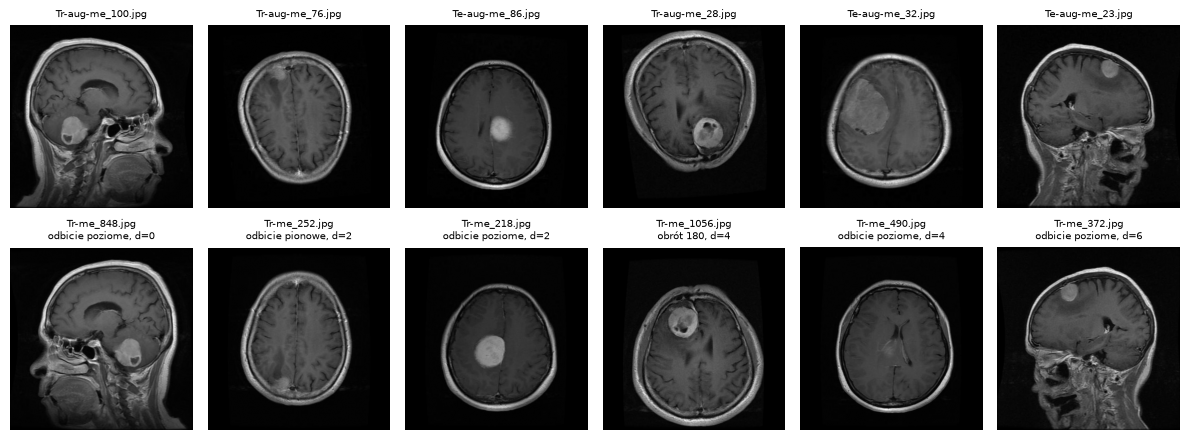

In [15]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for c, (_, row) in enumerate(match.sort_values('dist').iloc[::17].head(6).iterrows()):
    for s, key in enumerate(['aug', 'oryginal']):
        axes[s, c].imshow(Image.open(ROOT / row[key]).convert('L'), cmap='gray')
        axes[s, c].set_title(row[key].split('/')[-1] + (f"\n{row.przeksztalcenie}, d={row.dist}" if s else ''), fontsize=7)
        axes[s, c].axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_aug.png', dpi=110)
plt.show()

Pliki `aug` to odbite lub obrócone (czasem lekko przeskalowane) kopie oryginalnych oponiaków,
również takich z drugiego katalogu. Mieszanie takich kopii między treningiem i testem to wyciek.

### Decyzje
1. **Trening** = katalog `Training` bez plików `aug` (5500 obrazów: 1400/1300/1400/1400).
   Dysproporcja 1300 vs 1400 jest mała, więc nie stosujemy wag klas ani oversamplingu.
2. **Walidacja krzyżowa**: obrazy treningowe łączymy w grupy (spójne składowe grafu, w którym
   krawędź oznacza odległość pHash <= 4) i używamy **StratifiedGroupKFold** (K = 5), żeby kopie
   i sąsiednie przekroje nie trafiały jednocześnie do treningu i walidacji foldu. To przybliżenie
   walidacji grupowej (LOGO) z wykładu 4, gdy brak identyfikatora pacjenta.
3. **Test**: wyniki raportujemy na dwóch zbiorach:
   - oryginalnym `Testing` (1600 obrazów) - dla porównania z innymi pracami,
   - **oczyszczonym** `test_dedup` - bez obrazów mających bliźniaka w treningu i bez plików `aug`.

In [16]:
train_main = dup[(dup.split == 'Training') & ~dup.aug]
group_sizes = train_main.groupby('group').size()
print('grupy w treningu:', len(group_sizes), ', pojedyncze obrazy:', (group_sizes == 1).sum(),
      ', największa grupa:', group_sizes.max())
test_dedup = dup[dup.test_dedup]
pd.DataFrame({'Testing (oryginalny)': dup[dup.split == 'Testing'].cls.value_counts(),
              'test_dedup': test_dedup.cls.value_counts()}).loc[CLASSES]

grupy w treningu: 3928 , pojedyncze obrazy: 3165 , największa grupa: 22


,Testing (oryginalny),test_dedup
cls,,
glioma,400,314
meningioma,400,147
notumor,400,47
pituitary,400,298


Oczyszczony test jest mniejszy i niezbalansowany: zostało tylko kilkadziesiąt obrazów `notumor`,
bo prawie wszystkie testowe obrazy bez guza mają kopie w treningu. Dla tej klasy przedziały
ufności będą szerokie (bootstrap w notatniku 05).

## Podsumowanie EDA
- Zbiór jest sztucznie zbalansowany; klasę `meningioma` dopełniono kopiami (`aug`).
- Klasy różnią się rozdzielczością i jasnością, bo pochodzą z różnych źródeł - ryzyko uczenia
  się źródła zamiast guza.
- Między `Training` i `Testing` jest dużo duplikatów (370 identycznych, 714 przy progu 4),
  a w treningu są pary z różnymi etykietami.
- Odpowiedź: walidacja grupowa w treningu, oczyszczony test i analiza Grad-CAM.